# TP2 - Comptage de mots avec PySpark

Le but est de compter les mots avec PySpark et de comparer les temps avec Python.

## 1- Fichiers

J'utilise les quatre fichiers créés dans le TP1, avec un mot par ligne.

In [2]:
from pathlib import Path

tailles = [100, 1000, 10000, 100000]

for n in tailles:
    fichier = Path(f"mots_{n}.txt")
    if not fichier.exists():
        raise FileNotFoundError(f"Fichier manquant : {fichier}. Ouvre le notebook dans ~/TP_PySpark sous Ubuntu.")
    nb_lignes = len(fichier.read_text(encoding="utf-8").splitlines())
    assert nb_lignes == n
    print(f"{fichier} : {nb_lignes} lignes")

mots_100.txt : 100 lignes
mots_1000.txt : 1000 lignes
mots_10000.txt : 10000 lignes
mots_100000.txt : 100000 lignes


## 2- Python simple

Je compte les mots avec un dictionnaire Python.

In [3]:
def compter_python(fichier):
    with open(fichier, encoding="utf-8") as f:
        mots = f.read().split()

    compteur = {}
    for mot in mots:
        compteur[mot] = compteur.get(mot, 0) + 1
    return compteur

print(sorted(compter_python("mots_100.txt").items()))

[('arbre', 9), ('chat', 28), ('chien', 14), ('ciel', 4), ('fleur', 8), ('jardin', 2), ('livre', 4), ('lune', 3), ('maison', 6), ('mer', 3), ('montagne', 7), ('oiseau', 2), ('route', 3), ('soleil', 6), ('voiture', 1)]


## 3- PySpark

PySpark regroupe les mêmes mots et additionne leurs valeurs.

In [4]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.master("local[2]").appName("TP2_WordCount").getOrCreate()
spark.sparkContext.setLogLevel("ERROR")


def compter_pyspark(fichier):
    lignes = spark.sparkContext.textFile(str(Path(fichier).resolve()))
    mots = lignes.flatMap(lambda ligne: ligne.split())
    paires = mots.map(lambda mot: (mot, 1))
    return dict(paires.reduceByKey(lambda a, b: a + b).collect())

print(sorted(compter_pyspark("mots_100.txt").items()))

26/10/13 17:16:51 WARN Utils: Your hostname, LAPTOP-C314Q5B1 resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/13 17:16:51 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/13 17:16:52 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


[('arbre', 9), ('chat', 28), ('chien', 14), ('ciel', 4), ('fleur', 8), ('jardin', 2), ('livre', 4), ('lune', 3), ('maison', 6), ('mer', 3), ('montagne', 7), ('oiseau', 2), ('route', 3), ('soleil', 6), ('voiture', 1)]


## 4- Tests

Je vérifie que Python et PySpark trouvent les mêmes résultats pour chaque fichier.

In [7]:
for n in tailles:
    fichier = f"mots_{n}.txt"
    python = compter_python(fichier)
    pyspark = compter_pyspark(fichier)
    assert python == pyspark
    assert sum(pyspark.values()) == n
    print(f"{n} lignes : OK {len(pyspark)} mots différents")

100 lignes : OK 15 mots différents
1000 lignes : OK 15 mots différents
10000 lignes : OK 15 mots différents
100000 lignes : OK 15 mots différents


## 5- Comparaison des temps

Voici les temps mesurés dans le terminal Ubuntu avec `comparaison_pyspark.py`.

In [8]:
import csv

# Reprendre les mesures du terminal Ubuntu (déjà réalisées).
mesures = [
    {"Lignes": 100, "Python": 0.0003, "PySpark": 3.0407},
    {"Lignes": 1000, "Python": 0.0008, "PySpark": 0.6087},
    {"Lignes": 10000, "Python": 0.0032, "PySpark": 0.6041},
    {"Lignes": 100000, "Python": 0.0247, "PySpark": 0.6126},
]

# Si le fichier CSV est présent, on utilise directement ses valeurs.
if Path("resultats_pyspark.csv").exists():
    with open("resultats_pyspark.csv", encoding="utf-8", newline="") as f:
        mesures = [
            {"Lignes": int(l["Lignes"]), "Python": float(l["Python"]), "PySpark": float(l["PySpark"])}
            for l in csv.DictReader(f)
        ]

print("Lignes       Python       PySpark")
for l in mesures:
    print(f'{l["Lignes"]:>6}      {l["Python"]:.4f} s     {l["PySpark"]:.4f} s')

Lignes       Python       PySpark
   100      0.0003 s     3.0407 s
  1000      0.0008 s     0.6087 s
 10000      0.0032 s     0.6041 s
100000      0.0247 s     0.6126 s


## 6-Graphiques

Je représente les temps pour voir la différence entre les deux méthodes.

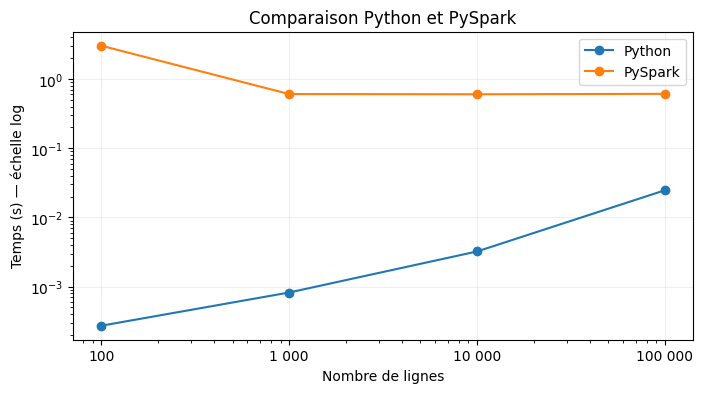

In [9]:
import matplotlib.pyplot as plt

x = [l["Lignes"] for l in mesures]
y_python = [l["Python"] for l in mesures]
y_spark = [l["PySpark"] for l in mesures]

plt.figure(figsize=(8, 4))
plt.plot(x, y_python, marker="o", label="Python")
plt.plot(x, y_spark, marker="o", label="PySpark")
plt.xscale("log")
plt.yscale("log")
plt.xticks(x, ["100", "1 000", "10 000", "100 000"])
plt.xlabel("Nombre de lignes")
plt.ylabel("Temps (s) — échelle log")
plt.title("Comparaison Python et PySpark")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

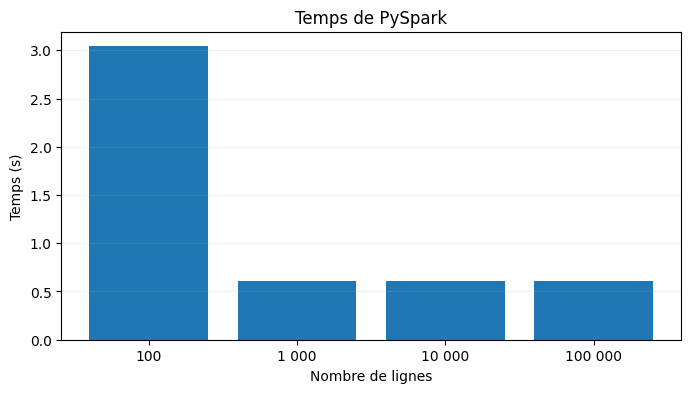

In [10]:
plt.figure(figsize=(8, 4))
plt.bar([str(n) for n in x], y_spark)
plt.xticks(range(len(x)), ["100", "1 000", "10 000", "100 000"])
plt.xlabel("Nombre de lignes")
plt.ylabel("Temps (s)")
plt.title("Temps de PySpark")
plt.grid(axis="y", alpha=0.2)
plt.show()

## 7- Conclusion

Les deux méthodes donnent les mêmes résultats. Python est plus rapide pour les fichiers testés. PySpark prend plus de temps au début, mais il permet de traiter des données en parallèle.

In [11]:
spark.stop()